# Force Model

The **force model** is the analytical representation of the overall forces acting on the satellite while travelling along its orbit, which can be represented by the following equation:

$$ \mathbf{F}_{sat} = m*\left ( \mathbf{a}_{centralBody} + \mathbf{a}_{otherBodies} + \mathbf{a}_{drag} + \mathbf{a}_{SRP} + \mathbf{a}_{thrust} + \mathbf{a}_{other}\right) $$

The above equation includes
- Earth gravity model (with harmonics up to a specific order/degrees)
- Tides
- Third body effects (mainly Sun and Moon, potentially all Solar System's bodies)
- Air drag (for LEO satellites only)
- Solar radiation pressure
- Albedo

Here below a quick explanation of the different accelerations involved:

## Earth Geopotential
This is the biggest contribution to the overall force model (assuming the Earth is the central body). Accordingly with the unperturbed Keplerian motion assumptions, the total mass of the Earth is concentrated in a single point:

-$$  \ddot{\mathbf{r}}=-\frac{GM}{r^{3}}\mathbf{r} = \nabla U\mapsto U=GM\frac{1}{r}$$ 

$U$ is the **gravity potential**. The assumption of the single point mass, as in the classical orbit determination approach is not sufficient anymore when performing optimal OD. The Earth's gravitational field is analytically described by an infinite number of elements (harmonics) which, if considered as whole, provide a point to point representation of the local gravitational acceleration acting on the satellite. In this case, the Earth geopotential can be represented as follows:

-$$ U = \frac{GM}{r}\sum_{n=0}^{\infty}\sum_{m=0}^{n}\frac{R_{\varnothing}}{r}P_{nm}\sin \phi \left ( C_{nm} \cos{m \lambda} + S_{nm} \sin{m \lambda}\right )$$

The coefficients $C_{nm}$ and $S_{nm}$ descibe the Earth's internal mass distribution. Geopotential coefficients with $m=0$ are called **zonal** coeffcients (which not depend on the longitude). The other geopotential coefficients are known as **tesseral** ($m<n$) and **sectorial** ($m=n$).
 Normally, the number of harmonics used to model the gravitational field is related to the orbit regime: the closer the satellite to the Earth's surface, the higher the number of harmonics to consider.

Because the internal mass distribution is not known, the geopotential coefficients have to be calculated from measurements and observations. The three main approaches are:

- Satellite tracking: the gravity field is determined through the perturbations seen in the satellite orbit
- Surface gravimetry: the local gravitation acceleration is measured usign static springs
- Altimeter data: the sea surface level is measured by using high-precision altimeters onboard the satellite


## Third Bodies
This term accounts for the gravitational attraction that any third body in the Solar system (mainly the Moon and the Sun) applies on the satellite. This perturbation can cause changes in eccentricity and inclination.
Even if it is a small contribution to the overall force, it gains more importance for geostationary satellites, since the related acceleration is out of the orbit plane.

The Figure above shows how the disturbance acceleration (due to the third body only) varies along the orbit in the inertial reference system. Both direction and magnitude change over time, depending on the position of the satellite along its orbit. The satellite experiences an acceleration away from the Earth whenever it is collinear with the Earth and the perturbing body, but is attracted towards the Earth whenever it is perpendicular to this line.

$\quad$

<center><img src="Images/thirdBody.png" alt="Drawing" style="width: 500px;"/><center>    


The acceleration disturbance effect by the third body is written as follows:
 $$\ddot{\mathbf{r}}=Gm\left ( \frac{\mathbf{s}-\mathbf{r}}{\left | s-r\right |^{3}} -\frac{\mathbf{s}}{s^{3}}\right )$$

$\quad$ 
 <center><img src="Images/ThirdBodyGravity_general.png" alt="Drawing" style="width: 600px;"/><center> 

## Solar Radiation Pressure
This terms derives from the absorption or reflection of photons hitting the satellite's surface, which provide an acceleration along the anti-Sun line. This contribution is also small, but became important for geostationary orbits as in the previous case.

The magnitue of the solar radiation pressure is determined by the **solar flux** $ \Phi$:

$$   P = \frac{ \Phi}{c} = \frac{\Delta E}{A c \Delta t} $$

, where $\Delta E$ is the energy which passes through an area $A$ in a time interval $\Delta t$ and $c$ is the speed of light.

An important parameter to consider is the **reflectivity coefficient** $\epsilon$ which varies from 0 (complete absorption) to 1 (complete specular reflection). Also, the **radiation pressure coefficient** is defined as: 

$$C_r = 1 + \epsilon$$

A simplified equation of the acceleration due to the solar radiation pressure can be written as:

$$  \ddot{\textbf{r}}=-P C_r\frac{A}{m}\frac{1}{r^2}\bar{\textbf{r}} $$

    

## Atmospheric Drag
This is the largest non-gravitational perturbation acting on low altitude satellites, and is particulary difficult to model for different resasons, maily because the physical properties of the atmosphere are not known exactly and the instantaneous orientation of the satellite body respect to the incoming air flux is not always known (especially for debris).

The satellite acceleration due to the drag can be written as follows:

$$ \ddot{\textbf{r}}=-\frac{1}{2}C_d\frac{A}{m} \rho v^2 \bar{\textbf{r}} $$

The **drag coefficient** $C_d$ is a dimensionless quantity that describes the interaction of the atmosphere with the satellite's surface material; tipical values are between 1.5 and 3. Its real value is difficult to define a priori, and it is one of the most important parameters to estimate during the OD process.

The area to mass ratio depends on the spacecraft attiude, as in the case of the Solar radiation pressure.

The **atmospheric density** $\rho$ at satellite location is another parameter difficult to model. Its value depend on the distribution of chemical constituents in the atmosphere and on its temperature, which in turn also depend on the Solar activity. The ultraviolet radiation produces a variation of the atmospheric density due to temperature changes. Specifically, the extreme ultraviolet radiation (10.7 cm wavelenght) is used as index (named **$F_{10.7}$**) since it has a significant impact on the Earth's upper atmosphere. The Figure below shos how its value is related to the 11-years period of the Solar cycle, which is characterized by the variation in sunspot numbers.

$\quad$
<center><img src="Images/F10.7.png" alt="Drawing" style="width: 500px;"/><center>    
    

The variation of solar flux strongly depends on solar activity. During periods of high solar activity, a large number of energetic particles were injected through the solar wind into the magnetosphere, and a portion of them penetrated the upper atmosphere, causing changes in plasma properties such as an increase in temperature and density. Changes in plasma properties around satellite altitude have a direct impact on the loss of orbital energy for orbiting satellites

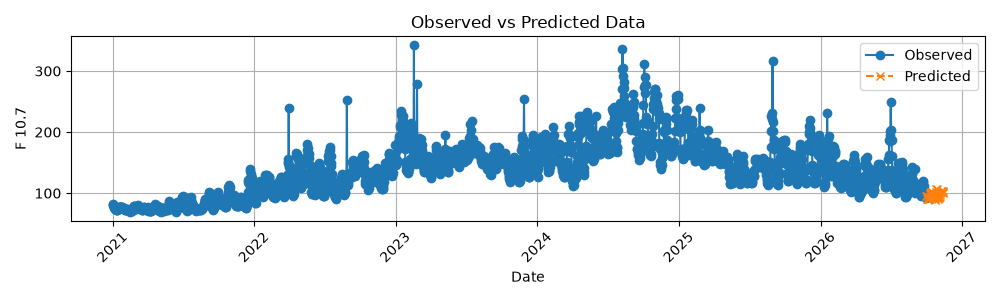

In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from resources import *
%matplotlib widget
file_path = 'Data/SpaceWeather-v1.2.txt'
plot_flux_index(file_path)

### Common Atmospheric Density Models in Orbit Determination

1. **NRLMSISE-00** (Naval Research Laboratory Mass Spectrometer and Incoherent Scatter Radar Extended)

- Type: Empirical model
- Description: This is one of the most widely used and recognized models. It provides neutral atmospheric temperatures and densities for various constituents (Helium, Oxygen, Nitrogen, etc.) from the ground up to around 1000 km altitude. It's an evolution of earlier MSIS models (like MSIS-86 and MSISE-90)
- Inputs: Requires geophysical parameters like solar flux indices (e.g., F10.7, both daily and 81-day average) and geomagnetic indices (e.g., Ap, Kp, Dst, which indicate geomagnetic activity levels), as well as time (Year, Day of Year, UTC time) and geographical position (altitude, latitude, longitude)
- Strengths: Widely validated, comprehensive in terms of atmospheric constituents, and generally provides good global average density values. Often considered the "industry standard" for many applications
- Limitations: Being empirical, its accuracy can be limited during extreme space weather events (solar flares, intense geomagnetic storms) due to the highly dynamic nature of the thermosphere
  
2. **Jacchia-Bowman** (JB2008, JB2006, Jacchia 1970)
   
- Type: Empirical models based on diffusion equations
- Description: The Jacchia series of models (with JB2008 being a more recent and improved revision) calculates atmospheric density and temperature using a similar set of solar and geomagnetic indices to NRLMSISE. They are based on Jacchia's diffusion equations, which describe how atmospheric constituents mix and diffuse
- Inputs: Similar to MSIS models, they rely on solar indices (often more detailed UV and X-ray irradiances) and geomagnetic indices
- Strengths: Historically significant and continue to be used. JB2008, for instance, aims to capture density variations during geomagnetic storms with greater resolution than some other models
- Limitations: Like other empirical models, they face challenges in predicting extreme space weather events accurately

4. **DTM** (Drag Temperature Model - e.g., DTM2000)

- Type: Semi-empirical model
- Description: DTM models describe the temperature, density, and composition of Earth's thermosphere. They combine theoretical considerations with extensive empirical data (often derived from satellite drag observations). DTM2000, for example, incorporates new data assimilation and constraints at lower atmospheric boundaries
- Inputs: Requires geographical and time information, as well as space weather data like solar flux (F10.7) and geomagnetic indices (Kp)
- Strengths: Offers a good balance between physical modeling and empirical data fitting. It has shown good performance for orbit determination and prediction, particularly for LEO targets
- Limitations: Similar to other empirical/semi-empirical models, its accuracy is influenced by the availability and quality of the driving space weather data

## Thrust 
This involves any internal acceleration due to thrusters (e.g., for orbit tranfer). The thrust can be expressed as follows:

$$  T = \dot{m}I_{sp}g_{0}  $$

where $\dot{m}$ is the fuel mass flow rate ans $I_{sp}$ is the specific impulse.

Even if the nominal thrust is known, most of the time the real performances of the onboard engines are slightly different and this introduces additional unknowns in the system.


## Disturbances Comparison

The Figure below (credits Satellite Orbits, Montenbruck-Gill) provides a visual representation (in logarithmic scale) of the magnitudes of the acceleration described above:

$\quad$

<center><img src="Images/accelerations.png" alt="Drawing" style="width: 450px;"/><center>

$\quad$

We can derive the following qualitative information:

- The effect of the gravitational field is bigger than any other effect for all possible orbit regime
- The overall effect of the gravitational attraction decreases when the altitude increases
- The effects of the third body attraction increase when the altitude increases
- Drag is the most important disturbance force at low altitudes
- At GEO regimes, the accelerations due to the Sun and the Moon have the same order of magnitude than the the first harmonic of the Earth gravitational field